# TD1 — Temporal data contract and forecasting baselines — Support

**Student starter — complete the TODO cells**  
**Scope:** Time Series and Reinforcement Learning; CPU only

## Working and claim contract

Local Python 3.11/3.12 with the locked `uv` environment is the primary path. Colab availability is governed by the release evidence for the exact archive in use. Public base seeds are `11, 23, 37, 51, 71`. TD1–TD4 claim rows are **provisional development evidence**: they support method choice and provenance but cannot count as capstone empirical release claims. Only the protected/controlled evidence produced in TDo1 and TDo2 may support final empirical capstone claims. Restart and run top-to-bottom before handoff.

## Support route

Guidance reduces syntax and navigation load; it does not expose the assessed solution or lower the Core standard.

In [1]:
from pathlib import Path
import os, sys

def locate_course_root(start=Path.cwd()):
    for candidate in [start, *start.parents]:
        if (candidate/'uv.lock').is_file() and (candidate/'shared').is_dir(): return candidate.resolve()
    for lock in start.glob('*/uv.lock'):
        if (lock.parent/'shared').is_dir(): return lock.parent.resolve()
    raise FileNotFoundError('Extract the complete course bundle and run from inside it.')
COURSE_ROOT=locate_course_root(); os.chdir(COURSE_ROOT)
if str(COURSE_ROOT) not in sys.path: sys.path.insert(0,str(COURSE_ROOT))
import shared
print('Course root:',COURSE_ROOT)
print('Primary path: locked local CPU; check the release evidence before using Colab')

Course root: D:\Documents\ESILV\A5\DIA\Machine learning\Advanced_Machine_Learning_ESILV_2026-2027_DVL_final
Primary path: locked local CPU; check the release evidence before using Colab


## Micro-example — lag-7 alignment

Complete the next-week forecast. The figure explains why forecast and target dates must align.

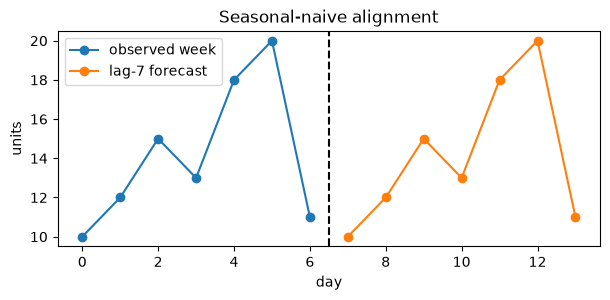

In [2]:
import numpy as np, matplotlib.pyplot as plt
toy_history=np.array([10,12,15,13,18,20,11],dtype=float)
toy_prediction=np.full(7,np.nan) # TODO: copy the final seasonal cycle
toy_prediction = toy_history[-7:].copy()
fig,ax=plt.subplots(figsize=(7,2.8)); ax.plot(range(7),toy_history,marker='o',label='observed week')
if np.isfinite(toy_prediction).all(): ax.plot(range(7,14),toy_prediction,marker='o',label='lag-7 forecast')
ax.axvline(6.5,color='black',ls='--'); ax.set(xlabel='day',ylabel='units',title='Seasonal-naive alignment'); ax.legend(); plt.show()

## 1 — Decision and data contract

In [5]:
import hashlib, numpy as np, pandas as pd
from sklearn.metrics import mean_absolute_error
from shared.data import dataset_path
from shared.evaluation import smape
path=dataset_path('daily_demand_development.csv')
demand=pd.read_csv(path,parse_dates=['date'])
data_sha256=hashlib.sha256(path.read_bytes()).hexdigest()
print(demand.shape,data_sha256[:16])
forecast_contract={'unit':'one calendar day','target':'demand_units','frequency':'daily','origin':None,'horizon_days':28,'known_at_origin':None,'protected_final_targets':True} # TODO
forecast_contract

(1433, 5) b275d65b07f44795


{'unit': 'one calendar day',
 'target': 'demand_units',
 'frequency': 'daily',
 'origin': None,
 'horizon_days': 28,
 'known_at_origin': None,
 'protected_final_targets': True}

## 2 — Executable invariants and negative test

Implement every check; do not delete the supplied expected-failure test.

In [6]:
def assert_daily_contract(frame):
    assert isinstance(frame,pd.DataFrame) and {'date','demand_units'}<=set(frame)
    d=frame['date']
    assert not d.duplicated().any(), 'duplicate dates'
    assert d.is_monotonic_increasing and (d.diff().dropna()>pd.Timedelta(0)).all(), 'dates not strictly increasing'
    assert (d.diff().dropna()==pd.Timedelta(days=1)).all(), 'gap in daily calendar'
    y=frame['demand_units'].to_numpy(float)
    assert np.isfinite(y).all(), 'target has NaN/inf'
    assert (y>=0).all(), 'negative demand'
    assert set(frame['stockout_flag'].unique())<={0,1}, 'stockout_flag not binary'
    assert len(frame)==1433, f'expected 1433 rows, got {len(frame)}'
    return True

print('Canonical data valid:',assert_daily_contract(demand))
print('Zeros:',int((demand.demand_units==0).sum()),'| missing:',int(demand.isna().sum().sum()),
      '| stockout days:',int(demand.stockout_flag.sum()))

negative_test_passed=False
try: assert_daily_contract(demand.iloc[[0,0,1]])
except AssertionError: negative_test_passed=True
print('Expected negative test caught:',negative_test_passed)

Canonical data valid: True
Zeros: 0 | missing: 0 | stockout days: 32
Expected negative test caught: True


## 3 — Freeze one public development block

In [7]:
train=demand.iloc[:-28].copy(); validation=demand.iloc[-28:].copy()
assert len(validation)==28 and train.date.max()<validation.date.min()
print(train.date.max(),validation.date.min())

2026-11-05 00:00:00 2026-11-06 00:00:00


## 4 — Three target-safe baselines

Fill only the three expressions; every value must come from training history.

In [9]:
def baseline_forecasts(train_values,horizon=28,season=7):
    train_values=np.asarray(train_values,float); assert len(train_values)>=season
    mean_forecast=np.full(horizon,train_values.mean())
    last_value_forecast=np.full(horizon,train_values[-1])
    seasonal_naive_forecast=np.tile(train_values[-season:],int(np.ceil(horizon/season)))[:horizon]
    values=[mean_forecast,last_value_forecast,seasonal_naive_forecast]
    if any(v is None for v in values): return None
    result=dict(zip(['historical_mean','last_value','seasonal_naive'],map(np.asarray,values)))
    assert all(v.shape==(horizon,) and np.isfinite(v).all() for v in result.values()); return result
forecasts=baseline_forecasts(train.demand_units.to_numpy())
print('Baselines pending' if forecasts is None else forecasts.keys())

dict_keys(['historical_mean', 'last_value', 'seasonal_naive'])


## 5 — Common metrics and explanatory figure

C:\Users\valen\AppData\Local\Temp\ipykernel_3940\3283147280.py:6: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  for name,pred in forecasts.items(): ax.plot(validation.date,pred,label=name,alpha=.8)


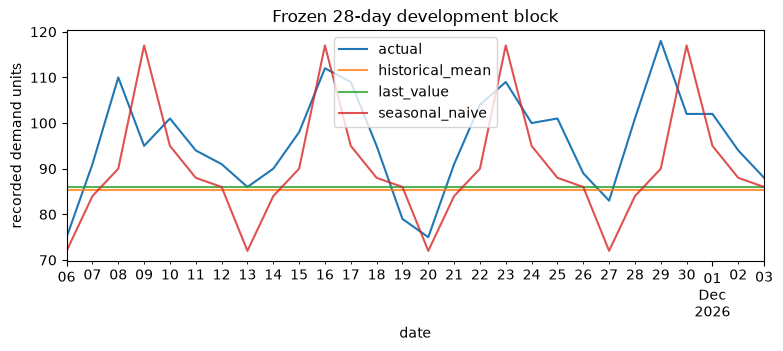

,model,mae,smape
0,historical_mean,12.557067,13.477491
1,last_value,12.107143,12.956200
2,seasonal_naive,9.607143,10.130650


In [10]:
scores=pd.DataFrame()
if forecasts is not None:
    actual=validation.demand_units.to_numpy(float)
    scores=pd.DataFrame([{'model':name,'mae':mean_absolute_error(actual,pred),'smape':smape(actual,pred)} for name,pred in forecasts.items()])
    ax=validation.plot(x='date',y='demand_units',figsize=(9,3),label='actual')
    for name,pred in forecasts.items(): ax.plot(validation.date,pred,label=name,alpha=.8)
    ax.set(title='Frozen 28-day development block',ylabel='recorded demand units'); ax.legend(); plt.show()
scores

## Required interpretation

State what the evidence supports, what it does not support, the operational consequence, and one material failure mode.

In [11]:
interpretation=(
 "On the frozen final 28 public development days (2026-11-06 to 2026-12-03), seasonal-naive lag-7 has the lowest error "
 "(MAE=9.61, sMAPE=10.13%), against 12.11 / 12.96% for last value and 12.56 / 13.48% for the historical mean, "
 "which is about 21% lower MAE than the best flat baseline. "
 "This supports a stable weekly cycle in recorded demand that constant forecasts cannot capture; "
 "it does not show that this ranking holds on other periods, because it rests on a single 28-day block with no uncertainty interval, "
 "and it says nothing about latent demand, since stockout_flag=1 days are censored recorded sales. "
 "Operationally, lag-7 becomes the reference that any later model must beat on the same block and dates, and the two flat baselines can be discarded. "
 "Material failure mode: lag-7 copies the last observed week and ignores the promotion calendar, so its errors concentrate on a few days. "
 "The five worst days (2026-11-08, 11-09, 11-28, 11-29, 11-30) carry about 38% of the total absolute error. "
 "Three of them are promotion days that were underforecast by 17 to 28 units, and the Monday peak of 117 from 2026-11-02 was repeated on later Mondays, "
 "overforecasting by 15 to 22 units."
)
print(interpretation)

On the frozen final 28 public development days (2026-11-06 to 2026-12-03), seasonal-naive lag-7 has the lowest error (MAE=9.61, sMAPE=10.13%), against 12.11 / 12.96% for last value and 12.56 / 13.48% for the historical mean, which is about 21% lower MAE than the best flat baseline. This supports a stable weekly cycle in recorded demand that constant forecasts cannot capture; it does not show that this ranking holds on other periods, because it rests on a single 28-day block with no uncertainty interval, and it says nothing about latent demand, since stockout_flag=1 days are censored recorded sales. Operationally, lag-7 becomes the reference that any later model must beat on the same block and dates, and the two flat baselines can be discarded. Material failure mode: lag-7 copies the last observed week and ignores the promotion calendar, so its errors concentrate on a few days. The five worst days (2026-11-08, 11-09, 11-28, 11-29, 11-30) carry about 38% of the total absolute error. Thre

## Bilan — TD1

### Where this lab sits

Time Series strand: **TD1 → TD2 → TDo1**.
- **TD1** compares simple forecasting methods on one public 28-day development block.
- **TD2** compares more advanced models on three development windows with a 14-day horizon, then **freezes the model-selection rule**.
- **TDo1** applies that frozen rule **once** to a separate, protected 28-day horizon. The earlier selection must not change after seeing the final evaluation.

The labs are development and practice; the TDo session is the controlled final evaluation. As in a real engineering project, a decision can only use the information available when it is made. Code may be corrected during development, but the experimental history is preserved and protected results are never used to improve an earlier frozen decision.

**TD1's role:** fix the data contract and set the simplest honest reference forecasts before any modelling.

### How the three baselines differ

| Baseline | What it assumes | What it misses |
|---|---|---|
| Historical mean | Tomorrow looks like the average of all past days | Trend, the permanent level shifts (indices 850 and 1,200), the weekly cycle. Its level (≈85 units) is far below the recent level (≈96 units). |
| Last value | Tomorrow looks like the last observed day | The weekly cycle. Its level is roughly right, but its quality depends on which weekday happened to be last. |
| Seasonal naive (lag 7) | Each day repeats the same weekday of last week | The promotion calendar, and the noise or one-off peaks it copies from last week (for example the Monday peak of 117 repeated on later Mondays) |

### Are these forecasts good or bad in absolute terms, not just against each other?

- The block averages **≈96 units/day** (standard deviation ≈10.7).
- **The two flat baselines are bad forecasts.** They miss by ≈12 units/day (≈13%). A flat line set at the *true* average of the block would score ≈8.7, so they are worse than the best possible constant: they capture neither the right level nor the weekly shape. They only serve as floors.
- **Seasonal naive is acceptable as a reference, but weak as an operational forecast.** It misses by ≈9.6 units/day (≈10%), barely better than that perfect-level flat line. Its errors are concentrated on *predictable* events: mean error is 18.3 on promotion days vs 8.2 on other days. An error of ~10 units/day over a month would require substantial safety stock.
- **Honest conclusion:** the weekly cycle is real, and any useful model must capture it. Beating the flat baselines is not enough; a useful model must also handle the trend, smooth out last week's noise rather than copy it, and ideally use the known promotion and holiday descriptors.

### Why a 28-day block?

- **Four complete weeks.** 28 is a multiple of the 7-day season, so every weekday appears exactly 4 times. A 30-day block would count two weekdays more often and bias the comparison toward models that happen to do well on those days.
- **About one month:** a realistic planning and replenishment horizon for demand.
- **Same format as the final test.** The protected TDo1 horizon is also 28 days, so TD1 rehearses exactly what the final evaluation will measure.
- **Limitation:** one block is one sample. This ranking may depend on the month chosen (November, with 4 promotion days). TD2 addresses this with several forecast origins.

### Carried forward

The daily data contract (no gaps or duplicates; stockout days are censored sales) and **seasonal naive lag-7 as the comparator** that TD2 models must beat.

## Optional Extension — ungraded

Freeze valid Core first. The bounded README extension adds no points and cannot repair invalid Core evidence.

In [12]:
val=validation.copy()
val['pred']=forecasts['seasonal_naive']
val['abs_err']=(val.demand_units-val.pred).abs()
print(val.nlargest(5,'abs_err')[['date','demand_units','pred','abs_err','promotion','holiday_period','stockout_flag']])
print(val.groupby('promotion')['abs_err'].agg(['count','mean']).round(2))
print('Top-5 share of total error:',round(val.nlargest(5,'abs_err').abs_err.sum()/val.abs_err.sum(),2))

           date  demand_units   pred  abs_err  promotion  holiday_period  \
1428 2026-11-29           118   90.0     28.0          1               0   
1408 2026-11-09            95  117.0     22.0          0               0   
1407 2026-11-08           110   90.0     20.0          1               0   
1427 2026-11-28           101   84.0     17.0          1               0   
1429 2026-11-30           102  117.0     15.0          0               0   

      stockout_flag  
1428              0  
1408              0  
1407              0  
1427              0  
1429              0  
           count   mean
promotion              
0             24   8.17
1              4  18.25
Top-5 share of total error: 0.38
